In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    return cutDataframe

In [3]:
def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

In [4]:
def calc_hist(vals, bins=10, weights=None, density=False):
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

In [5]:
def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

In [6]:
observables = ['runnumber', 'eventnumber', 'centrality', 'rho', 'jet_pt','jet_eta','jet_phi','jet_area','jet_neutral_fraction',\
               'jet_leading_track_pt','jet_leading_track_charge','jet_leading_track_y','jet_leading_track_phi',\
               'jet_subleading_track_pt','jet_subleading_track_charge','jet_subleading_track_y','jet_subleading_track_phi']

In [7]:
pythia_files = ['/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/50pthat1000_pythia.root',\
               '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/45pthat50_pythia.root',\
               '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/40pthat45_pythia.root',\
               '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/35pthat40_pythia.root',\
               '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/30pthat35_pythia.root',\
               '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/25pthat30_pythia.root',\
               '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/20pthat25_pythia.root',\
               '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/15pthat20_pythia.root',\
               '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/11pthat15_pythia.root']
embed_files = ['/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/50pthat1000_pythia_in_minbias.root',\
              '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/45pthat50_pythia_in_minbias.root',\
              '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/40pthat45_pythia_in_minbias.root',\
              '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/35pthat40_pythia_in_minbias.root',\
              '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/30pthat35_pythia_in_minbias.root',\
              '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/25pthat30_pythia_in_minbias.root',\
              '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/20pthat25_pythia_in_minbias.root',\
              '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/15pthat20_pythia_in_minbias.root',\
              '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/postcut/11pthat15_pythia_in_minbias.root']

In [8]:
initial_cut = 'jet_pt > 15 and jet_subleading_track_pt > 0 and centrality >= 12'

In [9]:
jet_pt_max_cut = [2000, 90, 80, 70, 60, 50, 40, 30, 22]

In [10]:
tot_w_array = np.array([7.1349,22.8423,94.4993,398.601,1774.42,8683.33,50010.2,379627.0,2557420.0]) # from r_dependence_pythia.ipynb
nevt_good_central = np.asarray([48488,48565,48751,48287,48629,48597,48392,48549,48535])
# qa_centrality->GetBinContent(14)+qa_centrality->GetBinContent(15)+qa_centrality->GetBinContent(16)+qa_centrality->GetBinContent(17)
w_array = tot_w_array/nevt_good_central
#w_array = np.array([0.00047249650000000005,0.001993005,0.0088721,0.04341665,0.25005099999999997,1.898135,12.7871])
# assume good event fraction and centrality distribution are the same across different runs

In [11]:
df_pythia_array = []
bad_eventnumber = []
for i in range(0, len(pythia_files)):
    df = applyCut(getData(observables, pythia_files[i], "jet_tree"), initial_cut)    
    # collect bad_eventnumber for high weight events
    df_highw = df[df.jet_pt>jet_pt_max_cut[i]]
    bad_eventnumber.append(np.asarray(df_highw['eventnumber']))
    # construct df from only good_events
    good_events = []
    for j in range(0, df.shape[0]):
        if (df.iloc[j]['eventnumber'] not in bad_eventnumber[i]):
            good_events.append(j)
    df = df.iloc[good_events]
    df['w'] = np.ones(df.shape[0])*w_array[i]
    df_pythia_array.append(df)
df_pythia = pd.concat([df for df in df_pythia_array])

In [12]:
bad_eventnumber

[array([], dtype=int32),
 array([], dtype=int32),
 array([], dtype=int32),
 array([], dtype=int32),
 array([], dtype=int32),
 array([], dtype=int32),
 array([3672830, 1447658], dtype=int32),
 array([ 838030, 1667548], dtype=int32),
 array([ 946201, 3613888, 3519702, 3341204,   15532,   39115,   92715,
        1034671, 1064006,  742166, 3220671, 3261027, 3270648, 3608902],
       dtype=int32)]

In [13]:
df_embed_array = []
for i in range(0, len(embed_files)):
    df = applyCut(getData(observables, embed_files[i], "jet_tree"), initial_cut + ' and jet_neutral_fraction < 0.9')
        # didn't nef cut on NEF for df_pythia, because a slightly different one was done in substructure.cxx. cutting on that\
        # again here for df_pythia leads to increase in fakes that are not due to background
    # construct df from only good_events
    good_events = []
    for j in range(0, df.shape[0]):
        if (df.iloc[j]['eventnumber'] not in bad_eventnumber[i]):
            good_events.append(j)
    df = df.iloc[good_events]
    df['w'] = np.ones(df.shape[0])*w_array[i]
    df_embed_array.append(df)
df_embed = pd.concat([df for df in df_embed_array])

In [14]:
df_pythia_evt = df_pythia.drop_duplicates(subset=['runnumber', 'eventnumber'], keep='first')
df_embed_evt = df_embed.drop_duplicates(subset=['runnumber', 'eventnumber'], keep='first')

In [15]:
run_number_array = [19118051,19118052,19118053,19118054,19118055,19118056,19118057,19118049,19118050]
n_pythia_evt_array = []
n_jet_per_pythia_evt_array = []
n_embed_evt_array = []
n_jet_per_embed_evt_array = []
avg_centrality = []
for run_number in run_number_array:
    n_pythia_evt_array.append(df_pythia_evt[df_pythia_evt.runnumber==run_number].shape[0])
    n_jet_per_pythia_evt_array.append(df_pythia[df_pythia.runnumber==run_number].shape[0]/df_pythia_evt[df_pythia_evt.runnumber==run_number].shape[0])
    n_embed_evt_array.append(df_embed_evt[df_embed_evt.runnumber==run_number].shape[0])
    n_jet_per_embed_evt_array.append(df_embed[df_embed.runnumber==run_number].shape[0]/df_embed_evt[df_embed_evt.runnumber==run_number].shape[0])
    avg_centrality.append(np.average(df_pythia_evt[df_pythia_evt.runnumber==run_number]['centrality']))

In [16]:
df_qa = pd.DataFrame(np.transpose([run_number_array,nevt_good_central[::-1],n_pythia_evt_array,n_jet_per_pythia_evt_array,n_embed_evt_array,n_jet_per_embed_evt_array,avg_centrality]),\
                    columns=['run ID','N(evt)','N(pythia evt)','N(jet/pythia evt)','N(embed evt)','N(jet/embed evt)','avg(centrality)'])
df_qa

,run ID,N(evt),N(pythia evt),N(jet/pythia evt),N(embed evt),N(jet/embed evt),avg(centrality)
0,19118051.0,48535.0,1177.0,1.007647,1176.0,5.705782,13.490229
1,19118052.0,48549.0,11973.0,1.089201,11960.0,5.780769,13.501879
2,19118053.0,48392.0,29446.0,1.243531,29404.0,5.812883,13.488759
3,19118054.0,48597.0,37416.0,1.357173,37380.0,5.937801,13.503127
4,19118055.0,48629.0,31324.0,1.457062,31315.0,5.938719,13.496520
5,19118056.0,48287.0,43170.0,1.543618,43160.0,6.022243,13.502108
6,19118057.0,48751.0,44988.0,1.617898,44979.0,6.047222,13.506157
7,19118049.0,48565.0,45799.0,1.693443,45789.0,6.090830,13.488679
8,19118050.0,48488.0,46775.0,1.784586,46771.0,6.154583,13.506189


In [17]:
df_embed.eval('jet_pt_sub = jet_pt - rho*jet_area', inplace=True)

Text(0, 0.5, 'number of jets')

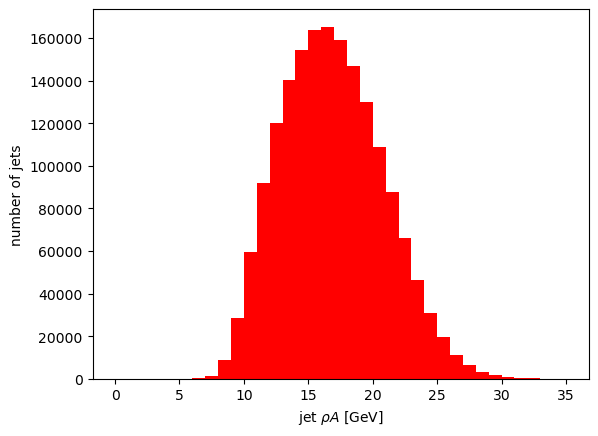

In [18]:
plt.hist(df_embed['rho']*df_embed['jet_area'], bins=np.arange(0,36),color='r')
plt.xlabel(r'jet $\rho A$ [GeV]')
plt.ylabel('number of jets')

In [19]:
df_embed_sub = applyCut(df_embed, 'jet_pt_sub > 15')

In [20]:
df_embed_sub

,runnumber,eventnumber,centrality,rho,jet_pt,jet_eta,jet_phi,jet_area,jet_neutral_fraction,jet_leading_track_pt,jet_leading_track_charge,jet_leading_track_y,jet_leading_track_phi,jet_subleading_track_pt,jet_subleading_track_charge,jet_subleading_track_y,jet_subleading_track_phi,w,jet_pt_sub
0,19118050,972332,15,49.151596,77.516907,-0.166111,1.344416,0.518612,0.316091,14.581533,1,-0.027697,1.381795,9.143879,-1,-0.399065,1.324921,0.000147,52.026291
1,19118050,972332,15,49.151596,71.302025,0.121762,4.514166,0.558505,0.453004,15.579208,1,0.108893,4.497229,8.340286,-1,0.115068,4.558970,0.000147,43.850594
9,19118050,972341,15,44.833080,73.614853,0.152616,4.043150,0.498666,0.241201,20.111698,-1,0.154665,4.032149,13.158230,1,0.181555,4.075732,0.000147,51.258141
57,19118050,972380,13,24.216578,71.959084,-0.150803,1.268587,0.488692,0.317732,10.664819,1,-0.134131,1.246811,9.769902,-1,-0.176550,1.260549,0.000147,60.124630
58,19118050,972380,13,24.216578,70.682617,-0.257443,4.382905,0.528585,0.529385,6.311680,-1,-0.238059,4.236941,5.462812,1,-0.313231,4.327429,0.000147,57.882088
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10141,19118051,3513938,13,24.104271,32.772957,0.544998,3.633040,0.508639,0.220975,6.082830,1,0.463189,3.653504,4.095303,-1,0.491003,3.530557,52.692284,20.512589
10153,19118051,3525965,12,26.787790,29.604561,-0.504558,2.755284,0.448799,0.632046,2.988089,-1,-0.618385,2.522271,1.981661,-1,-0.463513,2.704560,52.692284,17.582230
10160,19118051,3528881,13,31.105503,33.965755,-0.040682,1.002963,0.568479,0.418209,3.199151,1,-0.249464,1.016033,2.630692,1,0.018365,0.663047,52.692284,16.282942
10168,19118051,3532674,14,35.996288,45.268593,-0.372653,1.299000,0.508639,0.607547,3.079540,1,-0.491450,1.449827,2.232569,-1,-0.639282,1.454578,52.692284,26.959484


In [21]:
df_embed_sub.to_csv('embed_central.csv', index=False)

## Jet matching with $\Delta R(pythia, embed) < 0.4$

In [22]:
event_processed = 0
#embed_jet_processed = 0
matched_data = []
unmatched_data = []
for runnumber in np.unique(df_pythia_evt['runnumber']):
    for eventnumber in np.unique(df_pythia_evt[df_pythia_evt.runnumber == runnumber]['eventnumber']):
        event_processed += 1
        if (event_processed % 1000 == 0):
            print('processing event', event_processed)
        subdf_embed = df_embed_sub[(df_embed_sub.runnumber == runnumber) & (df_embed_sub.eventnumber == eventnumber)]
        subdf_pythia = df_pythia[(df_pythia.runnumber == runnumber) & (df_pythia.eventnumber == eventnumber)]
        matched_i = []
        matched_j = []
        for i in range(0, subdf_embed.shape[0]): # loop over all embedded jets in the event
            #embed_jet_processed += 1
            if (i in matched_i):
                continue
            eta_embed = subdf_embed.iloc[i]['jet_eta']
            phi_embed = subdf_embed.iloc[i]['jet_phi']
            matched = False
            for j in range(0, subdf_pythia.shape[0]): # loop over all pythia jets in the event
                if (j in matched_j):
                    continue
                deta = eta_embed - subdf_pythia.iloc[j]['jet_eta']
                dphi = phi_embed - subdf_pythia.iloc[j]['jet_phi']
                dr = np.sqrt(deta*deta + dphi*dphi)
                if (dr < 0.4):
                    matched = True
                    matched_i.append(i)
                    matched_j.append(j)
                    matched_data.append([subdf_pythia.iloc[j]['centrality'], subdf_pythia.iloc[j]['jet_pt'],\
                    subdf_pythia.iloc[j]['jet_leading_track_pt'], subdf_pythia.iloc[j]['jet_leading_track_charge'], subdf_pythia.iloc[j]['jet_leading_track_y'], subdf_pythia.iloc[j]['jet_leading_track_phi'],\
                    subdf_pythia.iloc[j]['jet_subleading_track_pt'], subdf_pythia.iloc[j]['jet_subleading_track_charge'], subdf_pythia.iloc[j]['jet_subleading_track_y'], subdf_pythia.iloc[j]['jet_subleading_track_phi'],\
                    subdf_embed.iloc[i]['rho'], subdf_embed.iloc[i]['jet_pt'], subdf_embed.iloc[i]['jet_area'], subdf_embed.iloc[i]['jet_pt_sub'],\
                    subdf_embed.iloc[i]['jet_leading_track_pt'],subdf_embed.iloc[i]['jet_leading_track_charge'],subdf_embed.iloc[i]['jet_leading_track_y'],subdf_embed.iloc[i]['jet_leading_track_phi'],\
                    subdf_embed.iloc[i]['jet_subleading_track_pt'],subdf_embed.iloc[i]['jet_subleading_track_charge'],subdf_embed.iloc[i]['jet_subleading_track_y'],subdf_embed.iloc[i]['jet_subleading_track_phi'],\
                    dr, subdf_embed.iloc[i]['jet_pt_sub']-subdf_pythia.iloc[j]['jet_pt'], subdf_pythia.iloc[j]['w']])
                    break
            if (matched == False):
                unmatched_data.append(subdf_embed.iloc[i])

processing event 1000
processing event 2000
processing event 3000
processing event 4000
processing event 5000
processing event 6000
processing event 7000
processing event 8000
processing event 9000
processing event 10000
processing event 11000
processing event 12000
processing event 13000
processing event 14000
processing event 15000
processing event 16000
processing event 17000
processing event 18000
processing event 19000
processing event 20000
processing event 21000
processing event 22000
processing event 23000
processing event 24000
processing event 25000
processing event 26000
processing event 27000
processing event 28000
processing event 29000
processing event 30000
processing event 31000
processing event 32000
processing event 33000
processing event 34000
processing event 35000
processing event 36000
processing event 37000
processing event 38000
processing event 39000
processing event 40000
processing event 41000
processing event 42000
processing event 43000
processing event 440

In [23]:
df_matched = pd.DataFrame(matched_data, columns=['centrality','jet_pt',\
                        'jet_leading_track_pt','jet_leading_track_charge', 'jet_leading_track_y', 'jet_leading_track_phi',\
                        'jet_subleading_track_pt','jet_subleading_track_charge','jet_subleading_track_y','jet_subleading_track_phi',\
                        'embed_rho','embed_jet_pt','embed_jet_area','embed_jet_pt_sub',\
                        'embed_jet_leading_track_pt','embed_jet_leading_track_charge','embed_jet_leading_track_y','embed_jet_leading_track_phi',\
                        'embed_jet_subleading_track_pt','embed_jet_subleading_track_charge','embed_jet_subleading_track_y','embed_jet_subleading_track_phi',\
                        'dr', 'dpt', 'w'])
df_unmatched = pd.DataFrame(unmatched_data)

In [24]:
frac_unmatched_20_25 = sum(df_unmatched[(df_unmatched.jet_pt_sub>20)&(df_unmatched.jet_pt_sub<25)]['w'])/(sum(df_unmatched[(df_unmatched.jet_pt_sub>20)&(df_unmatched.jet_pt_sub<25)]['w'])+sum(df_matched[(df_matched.embed_jet_pt_sub>20)&(df_matched.embed_jet_pt_sub<25)]['w']))
print('unmatched jet fraction:', frac_unmatched_20_25)

unmatched jet fraction: 0.01342964984786646


In [25]:
frac_unmatched_25_30 = sum(df_unmatched[(df_unmatched.jet_pt_sub>25)&(df_unmatched.jet_pt_sub<30)]['w'])/(sum(df_unmatched[(df_unmatched.jet_pt_sub>25)&(df_unmatched.jet_pt_sub<30)]['w'])+sum(df_matched[(df_matched.embed_jet_pt_sub>25)&(df_matched.embed_jet_pt_sub<30)]['w']))
print('unmatched jet fraction:', frac_unmatched_25_30)

unmatched jet fraction: 0.0058870017390103314


In [26]:
frac_unmatched_30_40 = sum(df_unmatched[(df_unmatched.jet_pt_sub>30)&(df_unmatched.jet_pt_sub<40)]['w'])/(sum(df_unmatched[(df_unmatched.jet_pt_sub>30)&(df_unmatched.jet_pt_sub<40)]['w'])+sum(df_matched[(df_matched.embed_jet_pt_sub>30)&(df_matched.embed_jet_pt_sub<40)]['w']))
print('unmatched jet fraction:', frac_unmatched_30_40)

unmatched jet fraction: 0.008690535862305398


## Matched jet QA

In [ ]:
plt.hist(df_matched['dr'], bins=np.arange(0,0.41,0.005), weights=df_matched['w'])
plt.xlabel('$\Delta R$(PYTHIA, embedded)')
plt.ylabel('arb. unit')

In [ ]:
plt.hist(df_matched['dpt'], bins=np.arange(-15,15.5,0.5), weights=df_matched['w'])
plt.xlabel('$p_{T,sub}$(embedded)$-p_T$(PYTHIA) [GeV]')
plt.ylabel('arb. unit')

In [74]:
rho_a_array = np.asarray(df_embed['rho']*df_embed['jet_area'])
print(rho_a_array)
np.random.shuffle(rho_a_array)
print(rho_a_array)
df_matched['random_rho_a'] = rho_a_array[:(df_matched.shape[0])]
df_matched.eval('jet_pt_refold = jet_pt + random_rho_a', inplace=True)

[25.490614 27.45143  23.529797 ... 12.965743 15.724411 14.896811]
[15.19117  13.231606 18.276958 ... 12.848982 13.759431 18.28035 ]


In [75]:
y_pythia, yerr_pythia = calc_hist(df_pythia['jet_pt'], bins=np.arange(15,50.5,0.5), weights=df_pythia['w'])[:2]
y_pythia_matched, yerr_pythia_matched = calc_hist(df_matched['jet_pt'], bins=np.arange(15,50.5,0.5), weights=df_matched['w'])[:2]
y_pythia_refold, yerr_pythia_refold = calc_hist(df_matched['jet_pt_refold'], bins=np.arange(15,50.5,0.5), weights=df_matched['w'])[:2]
y_embed, yerr_embed = calc_hist(df_embed['jet_pt'], bins=np.arange(15,50.5,0.5), weights=df_embed['w'])[:2]
y_embed_matched, yerr_embed_matched = calc_hist(df_matched['embed_jet_pt'], bins=np.arange(15,50.5,0.5), weights=df_matched['w'])[:2]
y_embed_sub, yerr_embed_sub = calc_hist(df_embed[df_embed.jet_pt_sub>15]['jet_pt_sub'], bins=np.arange(15,50.5,0.5), weights=df_embed[df_embed.jet_pt_sub>15]['w'])[:2]
y_embed_sub_matched, yerr_embed_sub_matched = calc_hist(df_matched['embed_jet_pt_sub'], bins=np.arange(15,50.5,0.5), weights=df_matched['w'])[:2]

(1, 200000.0)

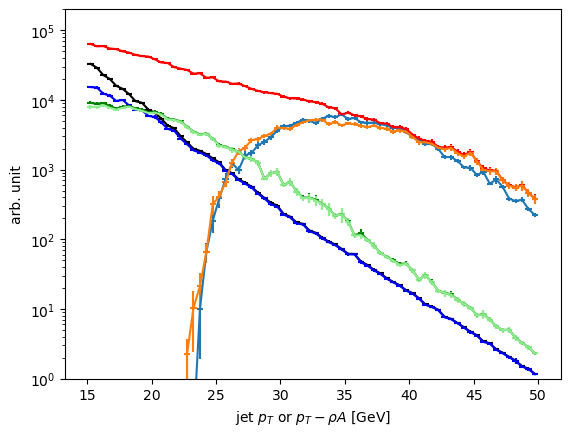

In [76]:
plt.errorbar(np.arange(15.25, 50.25, 0.5), y_pythia, xerr=0.25, yerr=yerr_pythia, label='PYTHIA ($p_T>15$ GeV)', color='k')
plt.errorbar(np.arange(15.25, 50.25, 0.5), y_pythia_matched, xerr=0.25, yerr=yerr_pythia_matched, label='PYTHIA ($p_T>15$ GeV), matched to Embed', color='b')
plt.errorbar(np.arange(15.25, 50.25, 0.5), y_pythia_refold, xerr=0.25, yerr=yerr_pythia_refold,  label='PYTHIA ($p_T>15$ GeV), matched to Embed, refolded')
plt.errorbar(np.arange(15.25, 50.25, 0.5), y_embed, xerr=0.25, yerr=yerr_embed,  label='Embed ($p_T>15$ GeV)', color='r')
plt.errorbar(np.arange(15.25, 50.25, 0.5), y_embed_matched, xerr=0.25, yerr=yerr_embed_matched, label='Embed ($p_T>15$ GeV), matched to PYTHIA')
plt.errorbar(np.arange(15.25, 50.25, 0.5), y_embed_sub, xerr=0.25, yerr=yerr_embed_sub, label='Embed ($p_{T,sub} > 15$ GeV)', color='g')
plt.errorbar(np.arange(15.25, 50.25, 0.5), y_embed_sub_matched, xerr=0.25, yerr=yerr_embed_sub_matched,  label='Embed ($p_{T,sub} > 15$ GeV), matched to PYTHIA', color='lightgreen')
plt.xlabel(r'jet $p_T$ or $p_T-\rho A$ [GeV]')
plt.ylabel('arb. unit')
#plt.legend(loc='lower left', framealpha=1)
plt.yscale('log')
plt.ylim(1, 2e5)

(1, 200000.0)

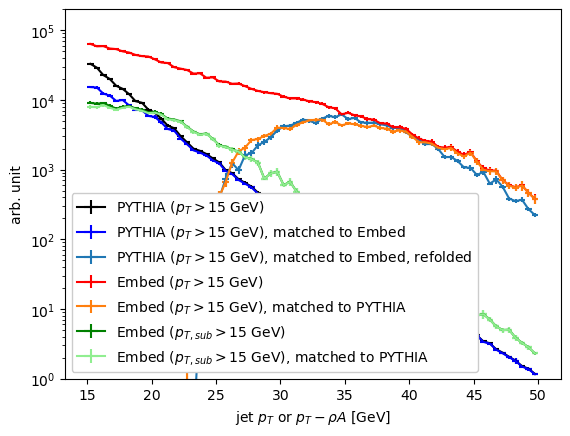

In [107]:
plt.errorbar(np.arange(15.25, 50.25, 0.5), y_pythia, xerr=0.25, yerr=yerr_pythia, label='PYTHIA ($p_T>15$ GeV)', color='k')
plt.errorbar(np.arange(15.25, 50.25, 0.5), y_pythia_matched, xerr=0.25, yerr=yerr_pythia_matched, label='PYTHIA ($p_T>15$ GeV), matched to Embed', color='b')
plt.errorbar(np.arange(15.25, 50.25, 0.5), y_pythia_refold, xerr=0.25, yerr=yerr_pythia_refold,  label='PYTHIA ($p_T>15$ GeV), matched to Embed, refolded')
plt.errorbar(np.arange(15.25, 50.25, 0.5), y_embed, xerr=0.25, yerr=yerr_embed,  label='Embed ($p_T>15$ GeV)', color='r')
plt.errorbar(np.arange(15.25, 50.25, 0.5), y_embed_matched, xerr=0.25, yerr=yerr_embed_matched, label='Embed ($p_T>15$ GeV), matched to PYTHIA')
plt.errorbar(np.arange(15.25, 50.25, 0.5), y_embed_sub, xerr=0.25, yerr=yerr_embed_sub, label='Embed ($p_{T,sub} > 15$ GeV)', color='g')
plt.errorbar(np.arange(15.25, 50.25, 0.5), y_embed_sub_matched, xerr=0.25, yerr=yerr_embed_sub_matched,  label='Embed ($p_{T,sub} > 15$ GeV), matched to PYTHIA', color='lightgreen')
plt.xlabel(r'jet $p_T$ or $p_T-\rho A$ [GeV]')
plt.ylabel('arb. unit')
plt.legend(loc='lower left', framealpha=1)
plt.yscale('log')
plt.ylim(1, 2e5)

## Matched jet leading di-tracks matching with $\Delta R(pythia, embed) = 0$

In [27]:
event_processed = 0
distance1 = []
distance2 = []
for i in range(0,df_matched.shape[0]):
    event_processed += 1
    if (event_processed % 1000 == 0):
        print('processing event', event_processed)
    phi1small = min(df_matched.iloc[i]['jet_leading_track_phi'], df_matched.iloc[i]['embed_jet_leading_track_phi'])
    phi1large = max(df_matched.iloc[i]['jet_leading_track_phi'], df_matched.iloc[i]['embed_jet_leading_track_phi'])
    phi2small = min(df_matched.iloc[i]['jet_subleading_track_phi'], df_matched.iloc[i]['embed_jet_subleading_track_phi'])
    phi2large = max(df_matched.iloc[i]['jet_subleading_track_phi'], df_matched.iloc[i]['embed_jet_subleading_track_phi'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df_matched.iloc[i]['jet_leading_track_phi'], df_matched.iloc[i]['embed_jet_leading_track_phi'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df_matched.iloc[i]['jet_leading_track_y']-df_matched.iloc[i]['embed_jet_leading_track_y'])**2))
    distance2.append(np.sqrt(dphi2**2+(df_matched.iloc[i]['jet_subleading_track_y']-df_matched.iloc[i]['embed_jet_subleading_track_y'])**2))
df_matched['distance1'] = distance1
df_matched['distance2'] = distance2

processing event 1000
processing event 2000
processing event 3000
processing event 4000
processing event 5000
processing event 6000
processing event 7000
processing event 8000
processing event 9000
processing event 10000
processing event 11000
processing event 12000
processing event 13000
processing event 14000
processing event 15000
processing event 16000
processing event 17000
processing event 18000
processing event 19000
processing event 20000
processing event 21000
processing event 22000
processing event 23000
processing event 24000
processing event 25000
processing event 26000
processing event 27000
processing event 28000
processing event 29000
processing event 30000
processing event 31000
processing event 32000
processing event 33000
processing event 34000
processing event 35000
processing event 36000
processing event 37000
processing event 38000
processing event 39000
processing event 40000
processing event 41000
processing event 42000
processing event 43000
processing event 440

processing event 347000
processing event 348000
processing event 349000
processing event 350000
processing event 351000
processing event 352000
processing event 353000
processing event 354000
processing event 355000
processing event 356000
processing event 357000
processing event 358000
processing event 359000
processing event 360000
processing event 361000
processing event 362000
processing event 363000
processing event 364000
processing event 365000
processing event 366000
processing event 367000
processing event 368000
processing event 369000
processing event 370000
processing event 371000
processing event 372000
processing event 373000
processing event 374000
processing event 375000
processing event 376000
processing event 377000
processing event 378000
processing event 379000
processing event 380000
processing event 381000
processing event 382000
processing event 383000
processing event 384000
processing event 385000
processing event 386000
processing event 387000
processing event

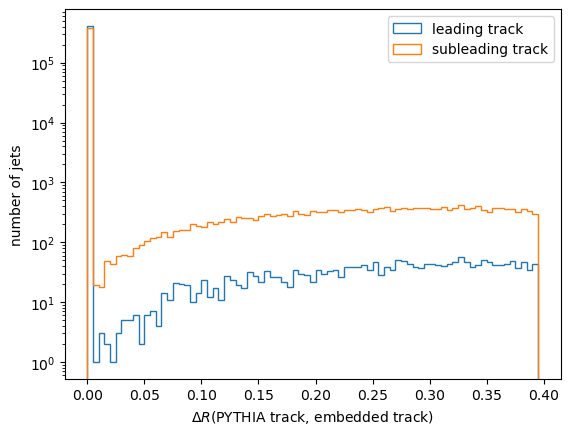

In [28]:
plt.hist(df_matched['distance1'], bins=np.arange(0,0.4,0.005), histtype='step', label='leading track')
plt.hist(df_matched['distance2'], bins=np.arange(0,0.4,0.005), histtype='step', label='subleading track')
plt.xlabel('$\Delta R$(PYTHIA track, embedded track)')
plt.ylabel('number of jets')
plt.yscale('log')
plt.legend()

In [28]:
frac_track_unmatched_20_25 = sum(df_matched[(df_matched.embed_jet_pt_sub>20) & (df_matched.embed_jet_pt_sub<25) & ((df_matched.distance1!=0) | (df_matched.distance2!=0))]['w'])/sum(df_matched[(df_matched.embed_jet_pt_sub>20) & (df_matched.embed_jet_pt_sub<25)]['w'])
frac_both_unmatched_20_25 = sum(df_matched[(df_matched.embed_jet_pt_sub>20) & (df_matched.embed_jet_pt_sub<25) & ((df_matched.distance1!=0) & (df_matched.distance2!=0))]['w'])/sum(df_matched[(df_matched.embed_jet_pt_sub>20) & (df_matched.embed_jet_pt_sub<25)]['w'])
print('fraction of at least one leading track unmatched:', frac_track_unmatched_20_25,\
      '\n -fraction of both leading tracks unmatched:', frac_both_unmatched_20_25)     

fraction of at least one leading track unmatched: 0.20691546733064772 
 -fraction of both leading tracks unmatched: 0.033971953672680764


In [29]:
frac_track_unmatched_25_30 = sum(df_matched[(df_matched.embed_jet_pt_sub>25) & (df_matched.embed_jet_pt_sub<30) & ((df_matched.distance1!=0) | (df_matched.distance2!=0))]['w'])/sum(df_matched[(df_matched.embed_jet_pt_sub>25) & (df_matched.embed_jet_pt_sub<30)]['w'])
frac_both_unmatched_25_30 = sum(df_matched[(df_matched.embed_jet_pt_sub>25) & (df_matched.embed_jet_pt_sub<30) & ((df_matched.distance1!=0) & (df_matched.distance2!=0))]['w'])/sum(df_matched[(df_matched.embed_jet_pt_sub>25) & (df_matched.embed_jet_pt_sub<30)]['w'])
print('fraction of at least one leading track unmatched:', frac_track_unmatched_25_30,\
      '\n -fraction of both leading tracks unmatched:', frac_both_unmatched_25_30)     

fraction of at least one leading track unmatched: 0.2174342444277124 
 -fraction of both leading tracks unmatched: 0.030856197733663788


In [30]:
frac_track_unmatched_30_40 = sum(df_matched[(df_matched.embed_jet_pt_sub>30) & (df_matched.embed_jet_pt_sub<40) & ((df_matched.distance1!=0) | (df_matched.distance2!=0))]['w'])/sum(df_matched[(df_matched.embed_jet_pt_sub>30) & (df_matched.embed_jet_pt_sub<40)]['w'])
frac_both_unmatched_30_40 = sum(df_matched[(df_matched.embed_jet_pt_sub>30) & (df_matched.embed_jet_pt_sub<40) & ((df_matched.distance1!=0) & (df_matched.distance2!=0))]['w'])/sum(df_matched[(df_matched.embed_jet_pt_sub>30) & (df_matched.embed_jet_pt_sub<40)]['w'])
print('fraction of at least one leading track unmatched:', frac_track_unmatched_30_40,\
      '\n -fraction of both leading tracks unmatched:', frac_both_unmatched_30_40)     

fraction of at least one leading track unmatched: 0.22223032166887446 
 -fraction of both leading tracks unmatched: 0.03623717793498188


In [31]:
print((1-frac_unmatched_20_25)*frac_both_unmatched_20_25, (1-frac_unmatched_20_25)*(frac_track_unmatched_20_25-frac_both_unmatched_20_25))

0.033515722230208725 0.17062094282608076


In [32]:
print((1-frac_unmatched_25_30)*frac_both_unmatched_25_30, (1-frac_unmatched_25_30)*(frac_track_unmatched_25_30-frac_both_unmatched_25_30))

0.03067454724394646 0.18547966140869956


In [33]:
print((1-frac_unmatched_30_40)*frac_both_unmatched_30_40, (1-frac_unmatched_30_40)*(frac_track_unmatched_30_40-frac_both_unmatched_30_40))

0.035922257440589175 0.18437676364813027


## Plot $r_c$

In [34]:
df_pythia.eval('b_ch = jet_leading_track_charge * jet_subleading_track_charge', inplace=True)
df_embed.eval('b_ch = jet_leading_track_charge * jet_subleading_track_charge', inplace=True)
df_matched.eval('b_ch = embed_jet_leading_track_charge * embed_jet_subleading_track_charge', inplace=True)
df_unmatched.eval('b_ch = jet_leading_track_charge * jet_subleading_track_charge', inplace=True)

In [45]:
df_matched_matched = applyCut(df_matched, 'distance1==0 and distance2==0')
df_matched.eval('distance_product = distance1*distance2', inplace=True)
df_matched_one_unmatched = applyCut(df_matched, '(distance1!=0 or distance2!=0) and distance_product==0')
df_matched_both_unmatched = applyCut(df_matched, 'distance1!=0 and distance2!=0')

In [46]:
print(sum(df_matched_one_unmatched['w'])/sum(df_matched['w']))

0.1745933542724461


In [47]:
df_pythia_array = [ df_pythia[(df_pythia.jet_pt>20) & (df_pythia.jet_pt<25)],\
                    df_pythia[(df_pythia.jet_pt>25) & (df_pythia.jet_pt<30)],\
                    df_pythia[(df_pythia.jet_pt>30) & (df_pythia.jet_pt<40)] ]

In [48]:
df_embed_array = [ df_embed[(df_embed.jet_pt_sub>20) & (df_embed.jet_pt_sub<25)],\
                    df_embed[(df_embed.jet_pt_sub>25) & (df_embed.jet_pt_sub<30)],\
                    df_embed[(df_embed.jet_pt_sub>30) & (df_embed.jet_pt_sub<40)] ]

In [49]:
df_embed_matched_array = [ df_matched[(df_matched.embed_jet_pt_sub>20) & (df_matched.embed_jet_pt_sub<25)],\
                    df_matched[(df_matched.embed_jet_pt_sub>25) & (df_matched.embed_jet_pt_sub<30)],\
                    df_matched[(df_matched.embed_jet_pt_sub>30) & (df_matched.embed_jet_pt_sub<40)] ]

In [50]:
df_embed_matched_matched_array = [ df_matched_matched[(df_matched_matched.embed_jet_pt_sub>20) & (df_matched_matched.embed_jet_pt_sub<25)],\
                    df_matched_matched[(df_matched_matched.embed_jet_pt_sub>25) & (df_matched_matched.embed_jet_pt_sub<30)],\
                    df_matched_matched[(df_matched_matched.embed_jet_pt_sub>30) & (df_matched_matched.embed_jet_pt_sub<40)] ]

In [51]:
df_embed_matched_one_unmatched_array = [ df_matched_one_unmatched[(df_matched_one_unmatched.embed_jet_pt_sub>20) & (df_matched_one_unmatched.embed_jet_pt_sub<25)],\
                    df_matched_one_unmatched[(df_matched_one_unmatched.embed_jet_pt_sub>25) & (df_matched_one_unmatched.embed_jet_pt_sub<30)],\
                    df_matched_one_unmatched[(df_matched_one_unmatched.embed_jet_pt_sub>30) & (df_matched_one_unmatched.embed_jet_pt_sub<40)] ]

In [52]:
df_embed_matched_both_unmatched_array = [ df_matched_both_unmatched[(df_matched_both_unmatched.embed_jet_pt_sub>20) & (df_matched_both_unmatched.embed_jet_pt_sub<25)],\
                    df_matched_both_unmatched[(df_matched_both_unmatched.embed_jet_pt_sub>25) & (df_matched_both_unmatched.embed_jet_pt_sub<30)],\
                    df_matched_both_unmatched[(df_matched_both_unmatched.embed_jet_pt_sub>30) & (df_matched_both_unmatched.embed_jet_pt_sub<40)] ]

In [53]:
df_embed_unmatched_array = [ df_unmatched[(df_unmatched.jet_pt_sub>20) & (df_unmatched.jet_pt_sub<25)],\
                    df_unmatched[(df_unmatched.jet_pt_sub>25) & (df_unmatched.jet_pt_sub<30)],\
                    df_unmatched[(df_unmatched.jet_pt_sub>30) & (df_unmatched.jet_pt_sub<40)] ]

In [54]:
rc_pythia_array = []
rc_err_pythia_array = []
for i in range(0, len(df_pythia_array)):
    rc_pythia_array.append(getRcAndErr(df_pythia_array[i], 'b_ch')[0])
    rc_err_pythia_array.append(getRcAndErr(df_pythia_array[i], 'b_ch')[1])

In [55]:
rc_embed_array = []
rc_err_embed_array = []
for i in range(0, len(df_embed_array)):
    rc_embed_array.append(getRcAndErr(df_embed_array[i], 'b_ch')[0])
    rc_err_embed_array.append(getRcAndErr(df_embed_array[i], 'b_ch')[1])

In [56]:
rc_embed_matched_array = []
rc_err_embed_matched_array = []
for i in range(0, len(df_embed_matched_array)):
    rc_embed_matched_array.append(getRcAndErr(df_embed_matched_array[i], 'b_ch')[0])
    rc_err_embed_matched_array.append(getRcAndErr(df_embed_matched_array[i], 'b_ch')[1])

In [57]:
rc_embed_matched_matched_array = []
rc_err_embed_matched_matched_array = []
for i in range(0, len(df_embed_matched_matched_array)):
    rc_embed_matched_matched_array.append(getRcAndErr(df_embed_matched_matched_array[i], 'b_ch')[0])
    rc_err_embed_matched_matched_array.append(getRcAndErr(df_embed_matched_matched_array[i], 'b_ch')[1])

In [58]:
rc_embed_matched_one_unmatched_array = []
rc_err_embed_matched_one_unmatched_array = []
for i in range(0, len(df_embed_matched_one_unmatched_array)):
    rc_embed_matched_one_unmatched_array.append(getRcAndErr(df_embed_matched_one_unmatched_array[i], 'b_ch')[0])
    rc_err_embed_matched_one_unmatched_array.append(getRcAndErr(df_embed_matched_one_unmatched_array[i], 'b_ch')[1])

In [59]:
rc_embed_matched_both_unmatched_array = []
rc_err_embed_matched_both_unmatched_array = []
for i in range(0, len(df_embed_matched_both_unmatched_array)):
    rc_embed_matched_both_unmatched_array.append(getRcAndErr(df_embed_matched_both_unmatched_array[i], 'b_ch')[0])
    rc_err_embed_matched_both_unmatched_array.append(getRcAndErr(df_embed_matched_both_unmatched_array[i], 'b_ch')[1])

In [60]:
rc_embed_unmatched_array = []
rc_err_embed_unmatched_array = []
for i in range(0, len(df_embed_unmatched_array)):
    rc_embed_unmatched_array.append(getRcAndErr(df_embed_unmatched_array[i], 'b_ch')[0])
    rc_err_embed_unmatched_array.append(getRcAndErr(df_embed_unmatched_array[i], 'b_ch')[1])

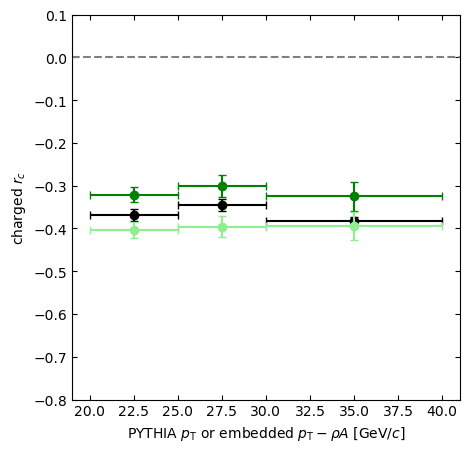

In [61]:
fig=plt.figure(figsize=(5,5))
plt.plot([22.5, 27.5, 35], rc_pythia_array, ls='none', marker='o', color='k')
plt.errorbar([22.5, 27.5, 35], rc_embed_array, ls='none', marker='o', color='g')
plt.errorbar([22.5, 27.5, 35], rc_embed_matched_matched_array, ls='none', marker='o', color='lightgreen')
#plt.errorbar([22.5, 27.5, 35], rc_embed_unmatched_array, ls='none', marker='o', color='r')
#plt.errorbar([22.5, 27.5, 35], rc_embed_matched_both_unmatched_array, ls='none', marker='o', color='chocolate')
#plt.errorbar([22.5, 27.5, 35], rc_embed_matched_one_unmatched_array, ls='none', marker='o', color='orange')
plt.errorbar([22.5, 27.5, 35], rc_pythia_array, xerr=[2.5, 2.5, 5], yerr=rc_err_pythia_array, capsize=3, ls='none', label='PYTHIA', color='k')
plt.errorbar([22.5, 27.5, 35], rc_embed_array, xerr=[2.5, 2.5, 5], yerr=rc_err_embed_array, capsize=3, ls='none', label='Embedded', color='g')
plt.errorbar([22.5, 27.5, 35], rc_embed_matched_matched_array, xerr=[2.5, 2.5, 5], yerr=rc_err_embed_matched_matched_array, capsize=3, ls='none', label='Embed jet matched, both leading tracks matched', color='lightgreen')
#plt.errorbar([22.5, 27.5, 35], rc_embed_unmatched_array, xerr=[2.5, 2.5, 5], yerr=rc_err_embed_unmatched_array, capsize=3, ls='none', label='Embed jet unmatched', color='r')
#plt.errorbar([22.5, 27.5, 35], rc_embed_matched_both_unmatched_array, xerr=[2.5, 2.5, 5], yerr=rc_err_embed_matched_both_unmatched_array, capsize=3, ls='none', label='Embed jet matched, both leading tracks unmatched', color='chocolate')
#plt.errorbar([22.5, 27.5, 35], rc_embed_matched_one_unmatched_array, xerr=[2.5, 2.5, 5], yerr=rc_err_embed_matched_one_unmatched_array, capsize=3, ls='none', label='Embed jet matched, one leading track unmatched', color='orange')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.xlabel(r'PYTHIA $p_{\mathrm{T}}$ or embedded $p_{\mathrm{T}}-\rho A$ [GeV$/c$]')
plt.ylabel('charged $r_c$')
plt.ylim(-0.8,0.1)
#plt.legend(fontsize=12, loc='lower left', frameon=True, framealpha=1)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')

In [93]:
print(rc_pythia_array)
print(rc_err_pythia_array)

[-0.36893897991928654, -0.345934101750401, -0.38240015067445154]
[0.014533269863054912, 0.013653540319919734, 0.009520975067970963]


In [90]:
print(rc_embed_matched_matched_array)
print(rc_err_embed_matched_matched_array)

[-0.40367403754857833, -0.39549948918052946, -0.3941586639740667]
[0.01905351511584069, 0.024993813716970254, 0.03175532488677084]


In [91]:
print(rc_embed_unmatched_array)
print(rc_err_embed_unmatched_array)

[-0.08732273837805661, -0.23069981953214125, -0.2841067034634731]
[0.15218053258829972, 0.22560610633590067, 0.31668758401165636]


In [92]:
print(rc_embed_matched_both_unmatched_array)
print(rc_err_embed_matched_both_unmatched_array)

[0.07750314831242171, 0.04138275698107638, 0.38306104427770904]
[0.11072054697316289, 0.1878019034707137, 0.13872733356298364]


In [62]:
print(rc_embed_matched_one_unmatched_array)
print(rc_err_embed_matched_one_unmatched_array)

[-0.04091564497284532, 0.04070514184093624, -0.17584050927203815]
[0.0443933568331472, 0.07477200444599852, 0.0613796434310973]


In [94]:
print(rc_embed_matched_array)
print(rc_err_embed_matched_array)

[-0.324590797461242, -0.30063275619109836, -0.3253887351840916]
[0.017732704969673815, 0.025844145470732043, 0.03344875891516718]
